In [6]:
import sys
sys.path.append("..")  # Lets the notebook find your 'src' folder

from src.preprocessing import load_and_clean_data, scale_features
from src.clustering import reduce_dimensions, train_kmeans

df = load_and_clean_data("../data/spotify_tracks.csv")
scaled_df, scaler = scale_features(df)

print(f"Loaded {len(df)} clean tracks! Scaled shape: {scaled_df.shape}")

Loaded 81343 clean tracks! Scaled shape: (81343, 9)


In [11]:
df.head()

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre,cluster
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic,4
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic,3
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic,6
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic,3
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic,3


In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 81343 entries, 0 to 81342
Data columns (total 22 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Unnamed: 0        81343 non-null  int64  
 1   track_id          81343 non-null  str    
 2   artists           81343 non-null  str    
 3   album_name        81343 non-null  str    
 4   track_name        81343 non-null  str    
 5   popularity        81343 non-null  int64  
 6   duration_ms       81343 non-null  int64  
 7   explicit          81343 non-null  bool   
 8   danceability      81343 non-null  float64
 9   energy            81343 non-null  float64
 10  key               81343 non-null  int64  
 11  loudness          81343 non-null  float64
 12  mode              81343 non-null  int64  
 13  speechiness       81343 non-null  float64
 14  acousticness      81343 non-null  float64
 15  instrumentalness  81343 non-null  float64
 16  liveness          81343 non-null  float64
 17  vale

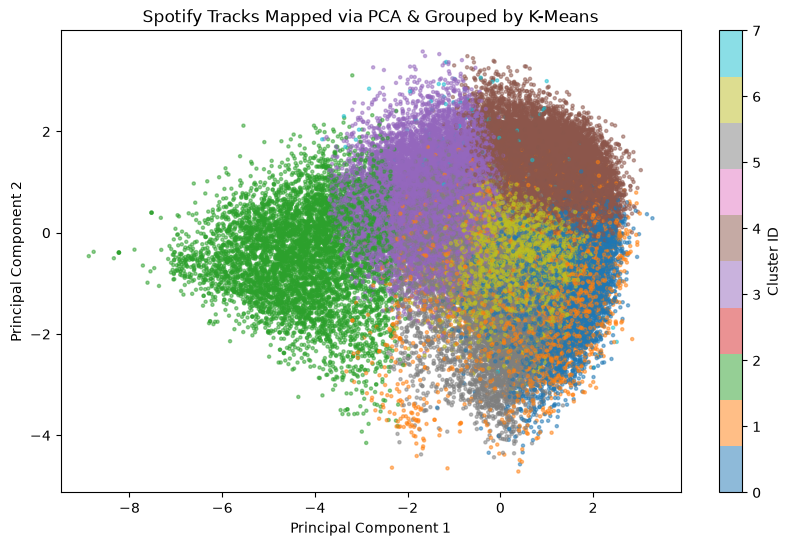

,danceability,energy,acousticness,tempo
cluster,,,,
0,0.47,0.82,0.11,163.18
1,0.51,0.75,0.30,122.89
2,0.34,0.17,0.86,102.23
3,0.53,0.36,0.73,114.43
4,0.72,0.71,0.25,117.98
5,0.58,0.74,0.11,126.71
6,0.53,0.75,0.10,108.82
7,0.57,0.68,0.75,100.44


In [13]:
import matplotlib.pyplot as plt

# 1. Run PCA (9 features -> 2D coordinates) & K-Means (8 vibe clusters)
reduced_features, pca = reduce_dimensions(scaled_df, n_components=2)
clusters, kmeans = train_kmeans(scaled_df, n_clusters=8)

# 2. Save cluster assignments back to our main DataFrame
df["cluster"] = clusters

# 3. Plot the 2D song map colored by cluster
plt.figure(figsize=(10, 6))
scatter = plt.scatter(
    reduced_features[:, 0], 
    reduced_features[:, 1], 
    c=clusters, 
    cmap="tab10", 
    alpha=0.5, 
    s=5
)
plt.title("Spotify Tracks Mapped via PCA & Grouped by K-Means")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(scatter, label="Cluster ID")
plt.show()

# 4. Inspect the average audio profile of each cluster
display(df.groupby("cluster")[["danceability", "energy", "acousticness", "tempo"]].mean().round(2))

In [14]:
from src.recommender import recommend_songs

# 1. Search for an Indian artist or track in your dataset (e.g., Arijit Singh)
indian_tracks = df[df["artists"].str.contains("Arijit Singh", case=False, na=False)]
display(indian_tracks[["track_name", "artists", "cluster"]].head())

# 2. Pick the first matching song and generate top 5 recommendations
sample_song = indian_tracks["track_name"].iloc[0]
print(f"🎧 Input Track: {sample_song} by {indian_tracks['artists'].iloc[0]}")

recommendations = recommend_songs(sample_song, df, scaled_df, top_n=5)
display(recommendations)

,track_name,artists,cluster
25340,"Kapoor & Sons Mashup (By DJ Chetas) (From ""Kap...",Nucleya;Benny Dayal;Amaal Mallik;Tanishk Bagch...,6
27611,Zinda Dili,Salim–Sulaiman;Arijit Singh,6
41698,Haareya,Sachin-Jigar;Arijit Singh;Priya Saraiya,3
43672,"Kesariya (From ""Brahmastra"")",Pritam;Arijit Singh;Amitabh Bhattacharya,3
43674,"Rasiya Reprise (From ""Brahmastra"")",Pritam;Arijit Singh;Amitabh Bhattacharya,3


🎧 Input Track: Kapoor & Sons Mashup (By DJ Chetas) (From "Kapoor & Sons (Since 1921)") by Nucleya;Benny Dayal;Amaal Mallik;Tanishk Bagchi;Badshah;Arko;Armaan Malik;Arijit Singh;Asees Kaur;Fazilpuria;Sukriti Kakar;Neha Kakkar


,track_name,artists,cluster,similarity_score
39411,Kundalini,Headhunterz;Skytech,6,0.989854
59386,Läuft bei Dir,Stefan Stürmer,6,0.984388
44973,Amerika,Rammstein,6,0.983884
20197,I Just Want Your Touch,Jolyon Petch;Starley,6,0.979337
59725,Micky Maus - Wir geh'n noch nicht nach Haus,Markus Becker,6,0.977258


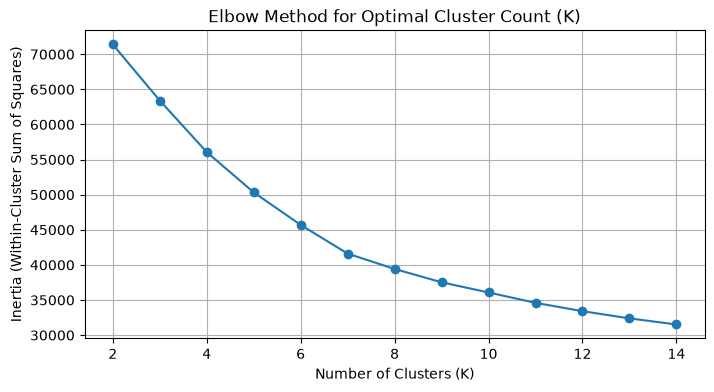

In [15]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertias = []
k_values = range(2, 15)

# Test K from 2 to 14 on a 10,000-song sample for speed
sample_scaled = scaled_df.sample(n=10000, random_state=42)

for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(sample_scaled)
    inertias.append(km.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(k_values, inertias, marker="o")
plt.title("Elbow Method for Optimal Cluster Count (K)")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia (Within-Cluster Sum of Squares)")
plt.grid(True)
plt.show()

In [18]:
with open("../.gitignore", "w") as f:
    f.write("data/*.csv\n__pycache__/\n")
print("Created .gitignore successfully!")

Created .gitignore successfully!
